In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
warnings.filterwarnings('ignore')

In [2]:
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv('hw4_course_lead_scoring_2026.csv')

In [4]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
df.shape

(5000, 9)

In [6]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [7]:
df.dtypes

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [8]:
categorical_cols = df.select_dtypes(include = ['object']).columns
print(categorical_cols)

Index(['lead_source', 'industry', 'employment_status', 'location'], dtype='object')


In [9]:
numerical_cols = df.select_dtypes(exclude = ['object']).columns.drop('converted') ## remove the target variable from the list of numerical columns
print(numerical_cols)

Index(['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score'],
      dtype='object')


In [10]:
for col in categorical_cols:
    df[col] = df[col].fillna("NA")

In [11]:
for col in numerical_cols:
    df[col] = df[col].fillna(0.0)

In [12]:
print(df.isnull().sum().sum())

0


In [13]:

(0.8-(0.8 *0.25)) * df.shape[0]

3000.0000000000005

In [14]:
df_full_train, df_test = train_test_split(df, test_size = 0.2, random_state  = 1)
df_train, df_val = train_test_split(df_full_train, test_size = 0.25, random_state = 1)

In [15]:
len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [16]:
## resetting the index of the dataframes
df_train = df_train.reset_index(drop = True)
df_val = df_val.reset_index(drop = True)
df_test = df_test.reset_index(drop = True)

In [17]:
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].to_numpy()

In [18]:
len(y_train), len(y_val), len(y_test)

(3000, 1000, 1000)

In [19]:
del df_train['converted']
del df_val['converted']
df_test.drop(columns = ['converted'], inplace = True)

In [20]:
'converted' in df_train.columns, 'converted' in df_val.columns, 'converted' in df_test.columns

(False, False, False)

In [21]:
numerical_cols

Index(['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score'],
      dtype='object')

## Q1

In [22]:
## Hw1
from sklearn.metrics import roc_auc_score
for col in numerical_cols:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = 1 - auc
    print(f"{col}: {auc:.4f}")

annual_income: 0.6082
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
lead_score: 0.7882


In [23]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Q2

In [24]:
##Q2
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Turning each dataframe into a list of row-dicts
train_dicts = df_train.to_dict(orient='records')
val_dicts   = df_val.to_dict(orient='records')

#One-hot encode via DictVectorizer
# fit on train (learn the schema), transform both
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val   = dv.transform(val_dicts)

# Train logistic regression on the encoded training data
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

# Predict probabilities on validation
# [:, 1] grabs the "probability of converted = 1" column
y_pred = model.predict_proba(X_val)[:, 1]

# Score the model
# Compute AUC against the true validation labels
auc = roc_auc_score(y_val, y_pred)
print(round(auc, 3))

0.732


## Q3

In [26]:
import numpy as np

thresholds = np.arange(0.0, 1.01, 0.01)
precisions = []
recalls = []

for t in thresholds:
    y_pred_class = (y_pred >= t).astype(int)   # 1 if >= threshold, else 0

    tp = ((y_pred_class == 1) & (y_val == 1)).sum()
    fp = ((y_pred_class == 1) & (y_val == 0)).sum()
    fn = ((y_pred_class == 0) & (y_val == 1)).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0

    precisions.append(precision)
    recalls.append(recall)

In [27]:
import pandas as pd

df_scores = pd.DataFrame({
    'threshold': thresholds,
    'precision': precisions,
    'recall': recalls
})


df_scores = df_scores[(df_scores['precision'] > 0) | (df_scores['recall'] > 0)] ##ignore rows where both are zero

df_scores['diff'] = (df_scores['precision'] - df_scores['recall']).abs()
best = df_scores.loc[df_scores['diff'].idxmin()]
print(best)

threshold    0.630000
precision    0.732759
recall       0.725256
diff         0.007503
Name: 63, dtype: float64


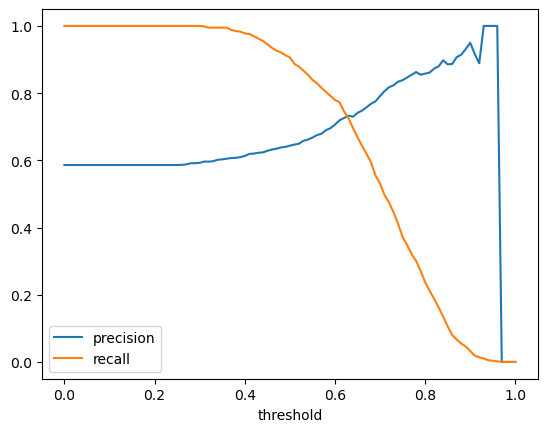

In [28]:
import matplotlib.pyplot as plt

plt.plot(thresholds, precisions, label='precision')
plt.plot(thresholds, recalls, label='recall')
plt.xlabel('threshold')
plt.legend()
plt.show()

## Q4

In [29]:
f1_scores = []

for p, r in zip(precisions, recalls):
    if (p + r) > 0:
        f1 = 2 * p * r / (p + r)
    else:
        f1 = 0
    f1_scores.append(f1)

In [30]:
best_idx = np.argmax(f1_scores)
print(f"Best threshold: {thresholds[best_idx]:.2f}")
print(f"Best F1: {f1_scores[best_idx]:.4f}")

Best threshold: 0.41
Best F1: 0.7576


## Q5

In [31]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold
import numpy as np

#  confirming df_full_train still has 'converted'
print("Columns in df_full_train:", df_full_train.columns.tolist())
print("Shape:", df_full_train.shape)
assert 'converted' in df_full_train.columns, "converted column missing from df_full_train"
print("Check 1 passed\n")



def train_and_score(df_train, df_val, y_train, y_val):
    train_dicts = df_train.to_dict(orient='records')
    val_dicts   = df_val.to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)
    X_val   = dv.transform(val_dicts)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    return roc_auc_score(y_val, y_pred)


kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []
fold_num = 0
for train_idx, val_idx in kfold.split(df_full_train):
    fold_num += 1

    df_tr = df_full_train.iloc[train_idx]
    df_vl = df_full_train.iloc[val_idx]

    print(f"Fold {fold_num}: train={len(df_tr)}, val={len(df_vl)}, total={len(df_tr)+len(df_vl)}")

    y_tr = df_tr['converted'].values
    y_vl = df_vl['converted'].values

    df_tr = df_tr.drop(columns=['converted'])
    df_vl = df_vl.drop(columns=['converted'])

    auc = train_and_score(df_tr, df_vl, y_tr, y_vl)
    scores.append(auc)
    print(f"         AUC = {auc:.4f}")


print("\nAll scores:", [round(s, 4) for s in scores])
print(f"Number of folds: {len(scores)}")
print(f"Mean AUC: {np.mean(scores):.4f}")
print(f"Std  AUC: {np.std(scores):.4f}")

Columns in df_full_train: ['lead_source', 'industry', 'employment_status', 'location', 'annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']
Shape: (4000, 9)
Check 1 passed

Fold 1: train=3200, val=800, total=4000
         AUC = 0.7306
Fold 2: train=3200, val=800, total=4000
         AUC = 0.7296
Fold 3: train=3200, val=800, total=4000
         AUC = 0.7363
Fold 4: train=3200, val=800, total=4000
         AUC = 0.7412
Fold 5: train=3200, val=800, total=4000
         AUC = 0.7209

All scores: [0.7306, 0.7296, 0.7363, 0.7412, 0.7209]
Number of folds: 5
Mean AUC: 0.7317
Std  AUC: 0.0069


## Q6

In [32]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold
import numpy as np

def train_and_score(df_train, df_val, y_train, y_val, C):
    train_dicts = df_train.to_dict(orient='records')
    val_dicts   = df_val.to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)
    X_val   = dv.transform(val_dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    return roc_auc_score(y_val, y_pred)


C_values = [0.000001, 0.001, 1]
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

results = []

for C in C_values:
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_tr = df_full_train.iloc[train_idx]
        df_vl = df_full_train.iloc[val_idx]

        y_tr = df_tr['converted'].values
        y_vl = df_vl['converted'].values

        df_tr = df_tr.drop(columns=['converted'])
        df_vl = df_vl.drop(columns=['converted'])

        auc = train_and_score(df_tr, df_vl, y_tr, y_vl, C)
        scores.append(auc)

    mean_auc = round(np.mean(scores), 3)
    std_auc  = round(np.std(scores), 3)
    results.append((C, mean_auc, std_auc))
    print(f"C={C:>10}: mean={mean_auc}, std={std_auc}")

print()
print("Best C by: highest mean, then lowest std, then smallest C")

C=     1e-06: mean=0.617, std=0.019
C=     0.001: mean=0.749, std=0.01
C=         1: mean=0.732, std=0.007

Best C by: highest mean, then lowest std, then smallest C
